

0. Setup Awal

In [1]:
# Library untuk K-Means, DBSCAN, visualisasi, dan ekspor Excel
%pip install numpy pandas scipy scikit-learn matplotlib seaborn openpyxl pillow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import time
import tracemalloc
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')

plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)

plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = 'outputKmeans'
os.makedirs(OUTPUT_DIR, exist_ok=True)

1. Data Understanding

1.1 Load Dataset

In [3]:
df = pd.read_csv('burnout_dataset1.csv')

print(f'Jumlah data awal: {len(df)}')

df = df.sample(
     n=5000,
     random_state=42
).reset_index(drop=True)

print(f'Jumlah data setelah sampling: {len(df)}')

df.head()

Jumlah data awal: 50000
Jumlah data setelah sampling: 5000


,Person_ID,Age,Gender,Country,Occupation,Education_Level,Employment_Status,Monthly_Income_USD,Work_Hours_Per_Week,Remote_Work,...,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score,Mental_Health_Status,AI_Wellness_Recommendation,Burnout_Risk
0,33554,19.0,Male,France,Teacher,PhD,Employed,NaN,58,Hybrid,...,No,No,Poor,7.0,53.0,26,52,Needs Attention,Reduce Workload,Moderate
1,9428,48.0,Male,Japan,Designer,Bachelor,Employed,NaN,53,Yes,...,Yes,No,Excellent,10.0,54.0,15,42,Needs Attention,Maintain Healthy Routine,Moderate
2,200,42.0,Male,United Kingdom,Police Officer,PhD,Unemployed,NaN,59,No,...,No,No,Average,6.0,50.0,28,46,Needs Attention,Increase Physical Activity,Moderate
3,12448,22.0,Other,Singapore,Lawyer,PhD,Student,NaN,49,Yes,...,No,Yes,Average,5.0,29.0,19,58,Needs Attention,Take Regular Breaks,Moderate
4,39490,62.0,Other,Russia,Doctor,Master,Self-Employed,NaN,39,Yes,...,Yes,No,Poor,1.0,62.0,30,50,Needs Attention,Take Regular Breaks,Moderate


1.2 Data Preview

In [4]:
print("5 Baris Pertama Dataset:")
display(df.head())

print("\nNama Semua Kolom:")
print(df.columns.tolist())

5 Baris Pertama Dataset:


,Person_ID,Age,Gender,Country,Occupation,Education_Level,Employment_Status,Monthly_Income_USD,Work_Hours_Per_Week,Remote_Work,...,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score,Mental_Health_Status,AI_Wellness_Recommendation,Burnout_Risk
0,33554,19.0,Male,France,Teacher,PhD,Employed,NaN,58,Hybrid,...,No,No,Poor,7.0,53.0,26,52,Needs Attention,Reduce Workload,Moderate
1,9428,48.0,Male,Japan,Designer,Bachelor,Employed,NaN,53,Yes,...,Yes,No,Excellent,10.0,54.0,15,42,Needs Attention,Maintain Healthy Routine,Moderate
2,200,42.0,Male,United Kingdom,Police Officer,PhD,Unemployed,NaN,59,No,...,No,No,Average,6.0,50.0,28,46,Needs Attention,Increase Physical Activity,Moderate
3,12448,22.0,Other,Singapore,Lawyer,PhD,Student,NaN,49,Yes,...,No,Yes,Average,5.0,29.0,19,58,Needs Attention,Take Regular Breaks,Moderate
4,39490,62.0,Other,Russia,Doctor,Master,Self-Employed,NaN,39,Yes,...,Yes,No,Poor,1.0,62.0,30,50,Needs Attention,Take Regular Breaks,Moderate



Nama Semua Kolom:
['Person_ID', 'Age', 'Gender', 'Country', 'Occupation', 'Education_Level', 'Employment_Status', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Remote_Work', 'Job_Satisfaction', 'Work_Life_Balance', 'Sleep_Hours', 'Sleep_Quality', 'Stress_Level', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Exercise_Frequency', 'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours', 'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Alcohol_Consumption', 'Smoking', 'Healthy_Diet', 'Chronic_Stress', 'Family_History_Mental_Illness', 'Therapy_Attendance', 'Support_System', 'Life_Satisfaction', 'Productivity_Score', 'Absenteeism_Days', 'Burnout_Score', 'Mental_Health_Status', 'AI_Wellness_Recommendation', 'Burnout_Risk']


1.3 Tipe data dan Missing Values

In [5]:
print('Tipe Data:')
print(df.dtypes)

print('\nJumlah Missing Value:')
missing = df.isnull().sum()

missing[missing > 0]

Tipe Data:
Person_ID                          int64
Age                              float64
Gender                               str
Country                              str
Occupation                           str
Education_Level                      str
Employment_Status                    str
Monthly_Income_USD               float64
Work_Hours_Per_Week                int64
Remote_Work                          str
Job_Satisfaction                 float64
Work_Life_Balance                float64
Sleep_Hours                      float64
Sleep_Quality                        str
Stress_Level                         str
Anxiety_Score                    float64
Depression_Score                 float64
Mood_Score                       float64
Emotional_Stability                int64
Physical_Activity_Hours          float64
Exercise_Frequency                   str
Meditation_Minutes               float64
Screen_Time_Hours                float64
Social_Media_Hours               float64
Gamin

Age                          28
Monthly_Income_USD         1450
Job_Satisfaction             37
Work_Life_Balance            60
Sleep_Hours                  85
Anxiety_Score                80
Depression_Score             73
Mood_Score                   91
Physical_Activity_Hours     100
Meditation_Minutes          122
Screen_Time_Hours            84
Social_Media_Hours           62
Gaming_Hours                 69
Therapy_Attendance           43
Life_Satisfaction            75
Productivity_Score           80
dtype: int64

1.4 Identifikasi Kolom yang Digunakan

In [6]:
# Kolom numerik asli
numeric_columns = df.select_dtypes(include='number').columns

# Menghapus identifier
numeric_columns = numeric_columns.drop(
    ['Person_ID', 'Burnout_Score'],
    errors='ignore'
)

# Kolom kategorikal yang akan di-encoding
categorical_columns = [
    'Remote_Work',
    'Sleep_Quality',
    'Stress_Level',
    'Exercise_Frequency',
    'Alcohol_Consumption',
    'Smoking',
    'Healthy_Diet',
    'Chronic_Stress',
    'Family_History_Mental_Illness',
    'Therapy_Attendance',
    'Support_System',
    'Mental_Health_Status'
]

print('Kolom Numerik:')
print(numeric_columns.tolist())

print('\nKolom Kategorikal yang akan di-encoding:')
print(categorical_columns)

Kolom Numerik:
['Age', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Job_Satisfaction', 'Work_Life_Balance', 'Sleep_Hours', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours', 'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Life_Satisfaction', 'Productivity_Score', 'Absenteeism_Days']

Kolom Kategorikal yang akan di-encoding:
['Remote_Work', 'Sleep_Quality', 'Stress_Level', 'Exercise_Frequency', 'Alcohol_Consumption', 'Smoking', 'Healthy_Diet', 'Chronic_Stress', 'Family_History_Mental_Illness', 'Therapy_Attendance', 'Support_System', 'Mental_Health_Status']


1.5 Statistik Deskriptif

In [7]:
df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,4972.0,41.684433,13.999166,18.0,29.00,42.0,54.00,65.0
Monthly_Income_USD,3550.0,6282.846197,3331.236477,500.0,3307.25,6370.5,9170.75,11998.0
Work_Hours_Per_Week,5000.0,45.032800,14.636945,20.0,32.00,45.0,58.00,70.0
Job_Satisfaction,4963.0,5.601048,2.876333,1.0,3.00,6.0,8.00,10.0
Work_Life_Balance,4940.0,5.520040,2.896089,1.0,3.00,6.0,8.00,10.0
Sleep_Hours,4915.0,6.956765,1.722117,4.0,5.50,6.9,8.40,10.0
Anxiety_Score,4920.0,40.857520,25.983071,0.0,20.00,40.0,60.00,100.0
Depression_Score,4927.0,41.036736,26.155498,0.0,20.00,40.0,60.00,100.0
Mood_Score,4909.0,59.207374,25.762049,0.0,41.00,59.0,80.00,100.0
Emotional_Stability,5000.0,59.003000,26.060461,0.0,40.00,60.0,80.00,100.0


1.6 Visualisasi Distribusi Data

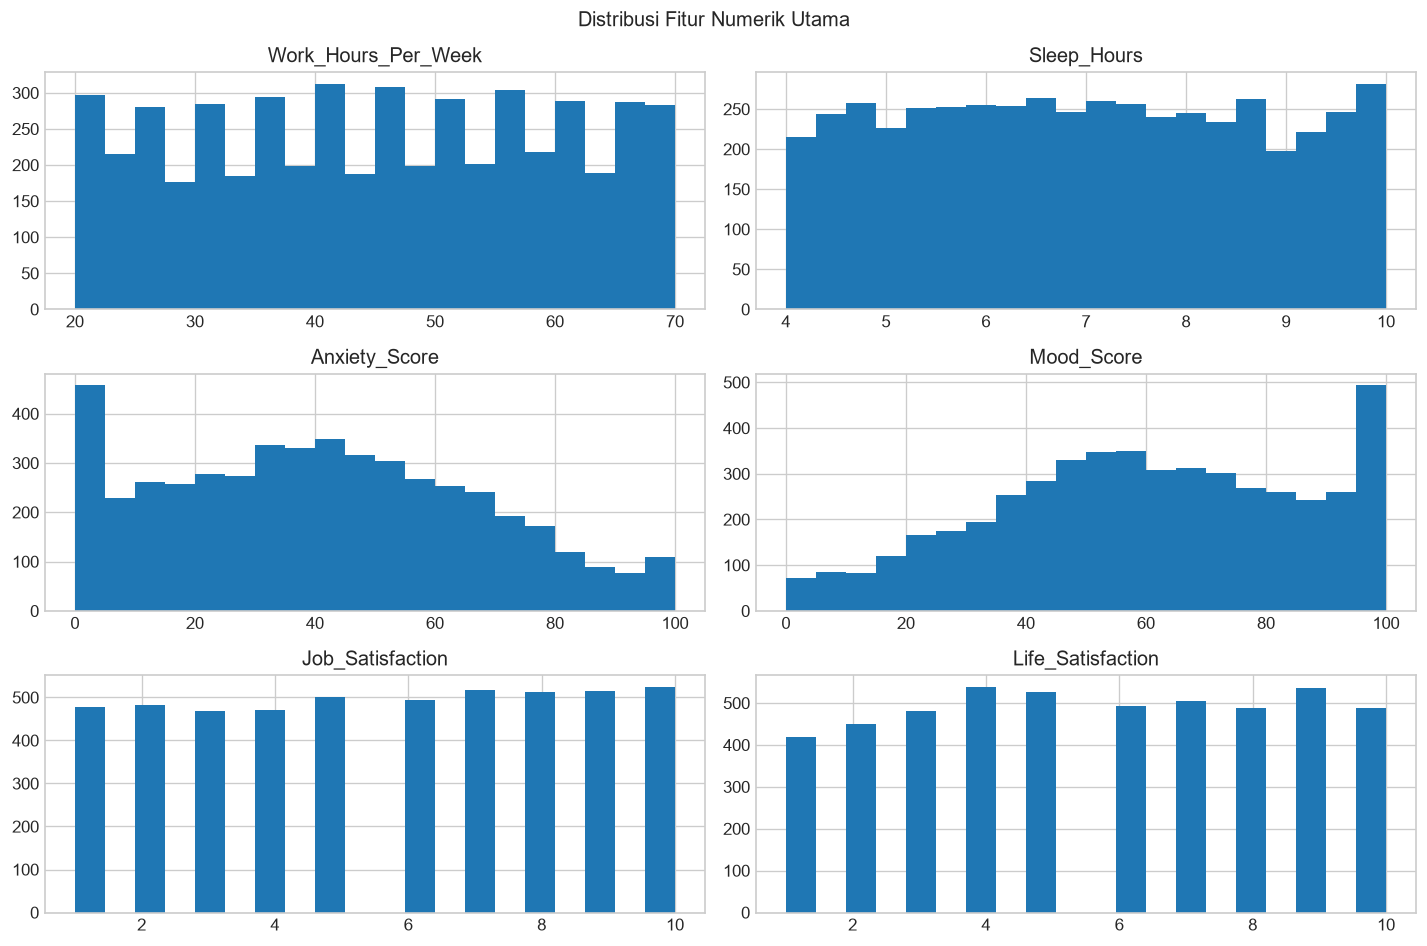

In [8]:
selected_features = [
    'Work_Hours_Per_Week',
    'Sleep_Hours',
    'Anxiety_Score',
    'Mood_Score',
    'Job_Satisfaction',
    'Life_Satisfaction'
]

df[selected_features].hist(
    figsize=(12, 8),
    bins=20
)

plt.suptitle('Distribusi Fitur Numerik Utama')
plt.tight_layout()
plt.show()

1.7 Visualisasi Deteksi Outlier

In [9]:
numeric_columns = df.select_dtypes(include='number').columns

numeric_columns = numeric_columns.drop(
    ['Person_ID', 'Burnout_Score'],
    errors='ignore'
)

numeric_data = df[numeric_columns]

Q1 = numeric_data.quantile(0.25)
Q3 = numeric_data.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (numeric_data < lower_bound) |
    (numeric_data > upper_bound)
)

In [10]:
outlier_summary = pd.DataFrame({
    'Jumlah Outlier': outlier_mask.sum(),
    'Persentase (%)': (
        outlier_mask.sum() / len(df) * 100
    ).round(2)
})

outlier_summary = outlier_summary.sort_values(
    'Jumlah Outlier',
    ascending=False
)

outlier_summary

,Jumlah Outlier,Persentase (%)
Age,0,0.0
Monthly_Income_USD,0,0.0
Work_Hours_Per_Week,0,0.0
Job_Satisfaction,0,0.0
Work_Life_Balance,0,0.0
Sleep_Hours,0,0.0
Anxiety_Score,0,0.0
Depression_Score,0,0.0
Mood_Score,0,0.0
Emotional_Stability,0,0.0


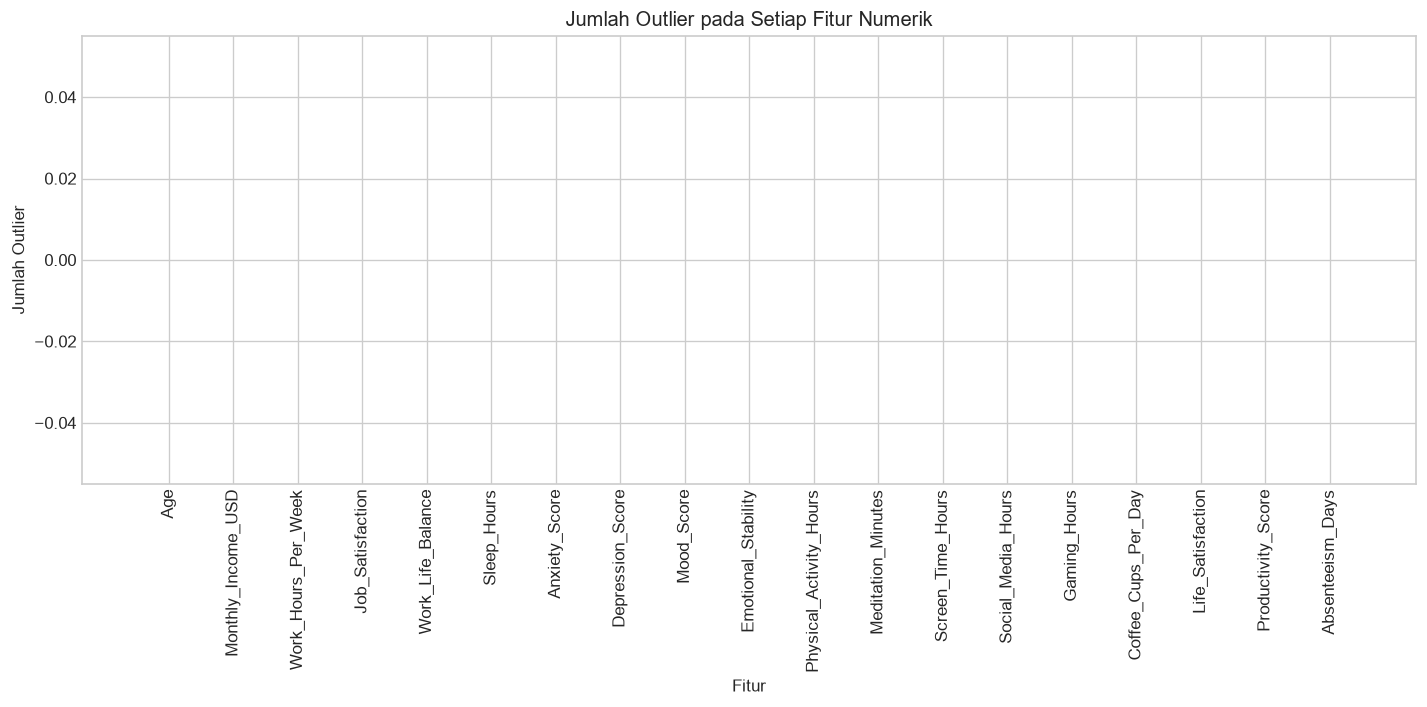

In [11]:
plt.figure(figsize=(12, 6))

plt.bar(
    outlier_summary.index,
    outlier_summary['Jumlah Outlier']
)

plt.title('Jumlah Outlier pada Setiap Fitur Numerik')
plt.xlabel('Fitur')
plt.ylabel('Jumlah Outlier')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [12]:
print(outlier_summary)

                         Jumlah Outlier  Persentase (%)
Age                                   0             0.0
Monthly_Income_USD                    0             0.0
Work_Hours_Per_Week                   0             0.0
Job_Satisfaction                      0             0.0
Work_Life_Balance                     0             0.0
Sleep_Hours                           0             0.0
Anxiety_Score                         0             0.0
Depression_Score                      0             0.0
Mood_Score                            0             0.0
Emotional_Stability                   0             0.0
Physical_Activity_Hours               0             0.0
Meditation_Minutes                    0             0.0
Screen_Time_Hours                     0             0.0
Social_Media_Hours                    0             0.0
Gaming_Hours                          0             0.0
Coffee_Cups_Per_Day                   0             0.0
Life_Satisfaction                     0         

2.1 Seleksi Kolom

In [13]:
selected_columns = list(numeric_columns) + categorical_columns

X = df[selected_columns].copy()

X.head()

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,19.0,NaN,58,8.0,9.0,9.6,56.0,35.0,54.0,37,...,Moderate,Never,Yes,No,No,No,No,No,Poor,Needs Attention
1,48.0,NaN,53,1.0,8.0,4.7,36.0,NaN,60.0,60,...,Moderate,Never,No,Yes,No,No,Yes,No,Excellent,Needs Attention
2,42.0,NaN,59,3.0,2.0,4.9,44.0,62.0,53.0,49,...,Moderate,Daily,No,Yes,No,No,No,No,Average,Needs Attention
3,22.0,NaN,49,9.0,8.0,6.3,72.0,65.0,29.0,35,...,High,Never,No,Yes,Yes,Yes,No,Yes,Average,Needs Attention
4,62.0,NaN,39,3.0,9.0,4.3,45.0,52.0,69.0,56,...,Moderate,Weekly,No,Yes,No,No,Yes,No,Poor,Needs Attention


2.2 Encoding Data Kategorikal

In [14]:
encoding_maps = {
    'Remote_Work': {
        'No': 0,
        'Hybrid': 1,
        'Yes': 2
    },

    'Sleep_Quality': {
        'Excellent': 0,
        'Good': 1,
        'Average': 2,
        'Poor': 3
    },

    'Stress_Level': {
        'Low': 0,
        'Moderate': 1,
        'High': 2
    },

    'Exercise_Frequency': {
        'Daily': 0,
        'Weekly': 1,
        'Rarely': 2,
        'Never': 3
    },

    'Alcohol_Consumption': {
        'No': 0,
        'Yes': 1
    },

    'Smoking': {
        'No': 0,
        'Yes': 1
    },

    'Healthy_Diet': {
        'No': 0,
        'Yes': 1
    },

    'Chronic_Stress': {
        'No': 0,
        'Yes': 1
    },

    'Family_History_Mental_Illness': {
        'No': 0,
        'Yes': 1
    },

    'Therapy_Attendance': {
        'No': 0,
        'Yes': 1
    },

    'Support_System': {
        'Poor': 0,
        'Average': 1,
        'Good': 2,
        'Excellent': 3
    },

    'Mental_Health_Status': {
        'Healthy': 0,
        'Needs Attention': 1,
        'Critical': 2
    }
}

for column, mapping in encoding_maps.items():
    X[column] = X[column].map(mapping)

X[categorical_columns].head()

,Remote_Work,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,1,0,1,3,1,0,0,0,0,0.0,0,1
1,2,3,1,3,0,1,0,0,1,0.0,3,1
2,0,3,1,0,0,1,0,0,0,0.0,1,1
3,2,2,2,3,0,1,1,1,0,1.0,1,1
4,2,3,1,1,0,1,0,0,1,0.0,0,1


2.3 Penanganan Missing Values

In [15]:
print('Missing value sebelum preprocessing:')
print(X.isnull().sum())

X = X.fillna(X.mean())

print(
    '\nJumlah missing value setelah preprocessing:',
    X.isnull().sum().sum()
)

Missing value sebelum preprocessing:
Age                                28
Monthly_Income_USD               1450
Work_Hours_Per_Week                 0
Job_Satisfaction                   37
Work_Life_Balance                  60
Sleep_Hours                        85
Anxiety_Score                      80
Depression_Score                   73
Mood_Score                         91
Emotional_Stability                 0
Physical_Activity_Hours           100
Meditation_Minutes                122
Screen_Time_Hours                  84
Social_Media_Hours                 62
Gaming_Hours                       69
Coffee_Cups_Per_Day                 0
Life_Satisfaction                  75
Productivity_Score                 80
Absenteeism_Days                    0
Remote_Work                         0
Sleep_Quality                       0
Stress_Level                        0
Exercise_Frequency                  0
Alcohol_Consumption                 0
Smoking                             0
Healthy_Diet 

2.4 Penanganan Outlier

In [16]:
# Karena tidak, tidak dilakukan

2.5 Standardisasi

In [17]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

X_scaled

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,-1.625133,0.000000,0.886011,0.837219,1.209004,1.548248,0.587561,-0.232529,-0.204019,-0.844390,...,0.390969,1.302823,1.031702,-0.989654,-0.982159,-0.403808,-0.973550,-1.014305,-1.351177,0.353005
1,0.452453,0.000000,0.544376,-1.605736,0.861585,-1.321877,-0.188482,0.000000,0.031054,0.038261,...,0.390969,1.302823,-0.969272,1.010455,-0.982159,-0.403808,1.027169,-1.014305,1.340769,0.353005
2,0.022608,0.000000,0.954338,-0.907749,-1.222929,-1.204729,0.121935,0.807484,-0.243198,-0.383877,...,0.390969,-1.360347,-0.969272,1.010455,-0.982159,-0.403808,-0.973550,-1.014305,-0.453862,0.353005
3,-1.410210,0.000000,0.271067,1.186213,0.861585,-0.384693,1.208396,0.923041,-1.183492,-0.921143,...,1.811640,1.302823,-0.969272,1.010455,1.018165,2.476422,-0.973550,0.994449,-0.453862,0.353005
4,1.455425,0.000000,-0.412204,-0.907749,1.209004,-1.556173,0.160737,0.422294,0.383664,-0.115244,...,0.390969,-0.472624,-0.969272,1.010455,-0.982159,-0.403808,1.027169,-1.014305,-1.351177,0.353005
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,0.667376,0.195668,1.705936,-1.605736,-0.180672,-0.618989,1.518814,2.001572,-1.575281,-1.343280,...,1.811640,-0.472624,1.031702,-0.989654,-0.982159,2.476422,-0.973550,-1.014305,0.443453,1.610144
4996,0.452453,-0.044840,-0.617185,-0.907749,0.166747,-0.618989,0.781572,0.345256,-0.282377,-0.959519,...,0.390969,-1.360347,1.031702,1.010455,1.018165,-0.403808,-0.973550,0.994449,-1.351177,0.353005
4997,-0.837083,-1.379573,1.159320,0.488225,0.861585,-1.497599,2.178451,1.616382,-2.202144,-2.187555,...,1.811640,-0.472624,-0.969272,1.010455,-0.982159,2.476422,-0.973550,-1.014305,-0.453862,1.610144
4998,0.452453,0.110154,1.569282,0.139232,-0.875510,-1.321877,0.083133,0.191180,-0.047304,0.076637,...,0.390969,-1.360347,-0.969272,1.010455,-0.982159,-0.403808,1.027169,-1.014305,1.340769,0.353005


2.6 Data Bersih

In [18]:
print('Dimensi data setelah preprocessing:', X.shape)
print('Jumlah missing value:', X.isnull().sum().sum())

X_scaled.head()

Dimensi data setelah preprocessing: (5000, 31)
Jumlah missing value: 0


,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,-1.625133,0.0,0.886011,0.837219,1.209004,1.548248,0.587561,-0.232529,-0.204019,-0.844390,...,0.390969,1.302823,1.031702,-0.989654,-0.982159,-0.403808,-0.973550,-1.014305,-1.351177,0.353005
1,0.452453,0.0,0.544376,-1.605736,0.861585,-1.321877,-0.188482,0.000000,0.031054,0.038261,...,0.390969,1.302823,-0.969272,1.010455,-0.982159,-0.403808,1.027169,-1.014305,1.340769,0.353005
2,0.022608,0.0,0.954338,-0.907749,-1.222929,-1.204729,0.121935,0.807484,-0.243198,-0.383877,...,0.390969,-1.360347,-0.969272,1.010455,-0.982159,-0.403808,-0.973550,-1.014305,-0.453862,0.353005
3,-1.410210,0.0,0.271067,1.186213,0.861585,-0.384693,1.208396,0.923041,-1.183492,-0.921143,...,1.811640,1.302823,-0.969272,1.010455,1.018165,2.476422,-0.973550,0.994449,-0.453862,0.353005
4,1.455425,0.0,-0.412204,-0.907749,1.209004,-1.556173,0.160737,0.422294,0.383664,-0.115244,...,0.390969,-0.472624,-0.969272,1.010455,-0.982159,-0.403808,1.027169,-1.014305,-1.351177,0.353005


3. Modeling

3.1 Penentuan Jumlah Klaster dengan Elbow Method

In [19]:
k_values = list(range(1, 11))
sse = []

for k in k_values:
    model_test = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        random_state=42
    )

    model_test.fit(X_scaled)

    sse.append(model_test.inertia_)

In [20]:
p1 = np.array([
    k_values[0],
    sse[0]
])

p2 = np.array([
    k_values[-1],
    sse[-1]
])

line_vec = p2 - p1
line_unit = line_vec / np.linalg.norm(line_vec)

distances = []

for k, inertia in zip(k_values, sse):

    point = np.array([
        k,
        inertia
    ])

    vec = point - p1

    projection = (
        np.dot(vec, line_unit)
        * line_unit
    )

    perpendicular = vec - projection

    distances.append(
        np.linalg.norm(perpendicular)
    )

n_clusters = 3

print(
    f'Jumlah Cluster untuk Pengujian: '
    f'k = {n_clusters}'
)

print(
    f'Jumlah Cluster Optimal: k = {n_clusters}'
)

Jumlah Cluster untuk Pengujian: k = 3
Jumlah Cluster Optimal: k = 3


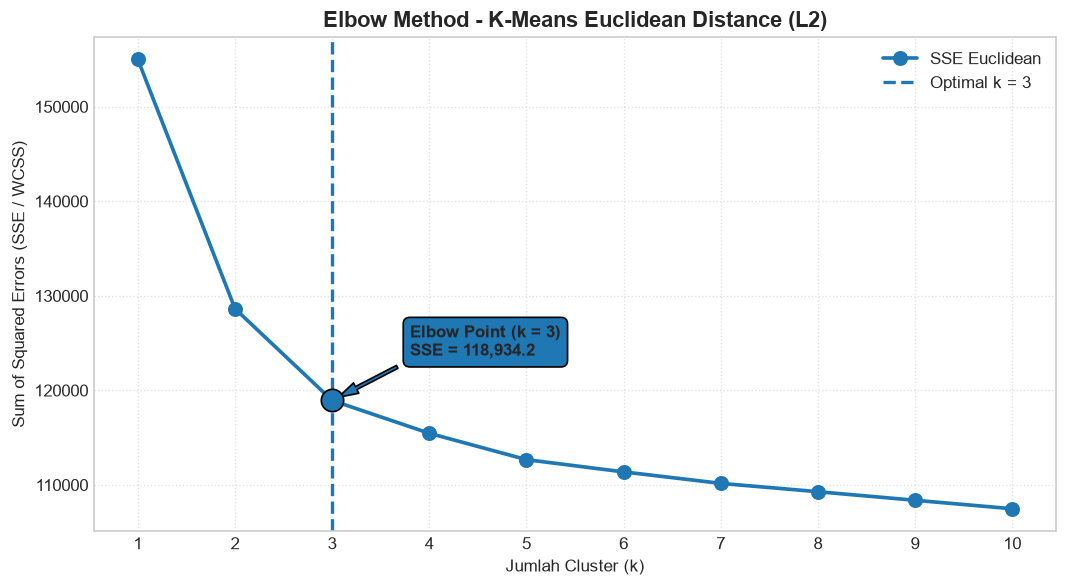

In [21]:
plt.figure(figsize=(9, 5))

plt.plot(
    k_values,
    sse,
    marker='o',
    markersize=8,
    linewidth=2.2,
    label='SSE Euclidean'
)

plt.axvline(
    x=n_clusters,
    linestyle='--',
    linewidth=2,
    label=f'Optimal k = {n_clusters}'
)

plt.scatter(
    [n_clusters],
    [sse[n_clusters - 1]],
    s=180,
    zorder=5,
    edgecolor='black'
)

plt.title(
    'Elbow Method - K-Means Euclidean Distance (L2)',
    fontsize=13,
    fontweight='bold'
)

plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Sum of Squared Errors (SSE / WCSS)')
plt.xticks(k_values)

plt.annotate(
    f'Elbow Point (k = {n_clusters})\n'
    f'SSE = {sse[n_clusters - 1]:,.1f}',
    xy=(
        n_clusters,
        sse[n_clusters - 1]
    ),
    xytext=(
        n_clusters + 0.8,
        sse[n_clusters - 1]
        + (max(sse) - min(sse)) * 0.1
    ),
    arrowprops=dict(
        shrink=0.08,
        width=2,
        headwidth=7
    ),
    bbox=dict(
        boxstyle='round,pad=0.4'
    ),
    fontweight='bold'
)

plt.grid(
    True,
    linestyle=':',
    alpha=0.6
)

plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        'elbow_euclidean.png'
    ),
    dpi=300
)

plt.show()

3.2 Training K-Means Euclidian

In [22]:
tracemalloc.start()

start_time = time.perf_counter()

kmeans = KMeans(
    n_clusters=n_clusters,
    init='k-means++',
    n_init=10,
    max_iter=300,
    tol=1e-4,
    random_state=42
)

kmeans.fit(X_scaled)

runtime = (
    time.perf_counter()
    - start_time
)

current_memory, peak_memory = (
    tracemalloc.get_traced_memory()
)

tracemalloc.stop()

peak_memory_mb = (
    peak_memory / (1024 ** 2)
)

labels = kmeans.labels_

df['KMeans_Cluster'] = labels

In [23]:
iterations = kmeans.n_iter_
sse_final = kmeans.inertia_

print(
    f'Runtime     : {runtime:.5f} detik'
)

print(
    f'Iterations  : {iterations}'
)

print(
    f'SSE         : {sse_final:.2f}'
)

print(
    f'Peak Memory : {peak_memory_mb:.2f} MB'
)

Runtime     : 0.15990 detik
Iterations  : 9
SSE         : 118934.23
Peak Memory : 2.43 MB


4. Evaluasi

4.1 Silhouette Score

In [24]:
silhouette = float(
    silhouette_score(
        X_scaled,
        labels,
        metric='euclidean'
    )
)

print(
    f'Silhouette Score: '
    f'{silhouette:.4f}'
)

Silhouette Score: 0.1115


4.2 Davies-Bouldin Index

In [25]:
db_index = float(
    davies_bouldin_score(
        X_scaled,
        labels
    )
)

print(
    f'Davies-Bouldin Index: '
    f'{db_index:.4f}'
)

Davies-Bouldin Index: 2.4867


4.3 Calinski-Harabasz Index

In [26]:
ch_index = float(
    calinski_harabasz_score(
        X_scaled,
        labels
    )
)

print(
    f'Calinski-Harabasz Index: '
    f'{ch_index:.2f}'
)

Calinski-Harabasz Index: 757.65


4.4 Distribusi Cluster

In [27]:
cluster_distribution = (
    df['KMeans_Cluster']
    .value_counts()
    .sort_index()
)

cluster_distribution

KMeans_Cluster
0     705
1    2125
2    2170
Name: count, dtype: int64

4.5 Ringkasan Evaluasi

In [28]:
model_summary = pd.DataFrame([{
    'Model': 'K-Means Euclidean',

    'Distance Metric':
        'Euclidean Distance (L2)',

    'Jumlah Cluster':
        n_clusters,

    'Silhouette Score (↑)':
        round(silhouette, 4),

    'Davies-Bouldin Index (↓)':
        round(db_index, 4),

    'Calinski-Harabasz Index (↑)':
        round(ch_index, 2),

    'Execution Time (s) (↓)':
        round(runtime, 5),

    'Iterations (↓)':
        iterations,

    'Objective Value (SSE) (↓)':
        round(sse_final, 2),

    'Alokasi Memori (MB)':
        round(peak_memory_mb, 2)
}])

model_summary

,Model,Distance Metric,Jumlah Cluster,Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑),Execution Time (s) (↓),Iterations (↓),Objective Value (SSE) (↓),Alokasi Memori (MB)
0,K-Means Euclidean,Euclidean Distance (L2),3,0.1115,2.4867,757.65,0.1599,9,118934.23,2.43


4.6 Export Hasil

In [29]:
excel_path = os.path.join(
    OUTPUT_DIR,
    'evaluasi_kmeans_euclidean.xlsx'
)

df_clustered = df.copy()

df_clustered[
    'KMeans_Cluster'
] = labels

with pd.ExcelWriter(
    excel_path,
    engine='openpyxl'
) as writer:

    model_summary.to_excel(
        writer,
        sheet_name='Ringkasan_Evaluasi',
        index=False
    )

    df_clustered.to_excel(
        writer,
        sheet_name='Data_Terklaster',
        index=False
    )

print(
    f'Hasil disimpan ke: {excel_path}'
)

Hasil disimpan ke: outputKmeans\evaluasi_kmeans_euclidean.xlsx


5. Reduksi Dimensi PCA

5.1 PCA

In [30]:
pca = PCA(
    n_components=2
)

X_pca = pca.fit_transform(
    X_scaled
)

centroids_pca = pca.transform(
    kmeans.cluster_centers_
)

5.2 Visualisasi Hasil Klaster

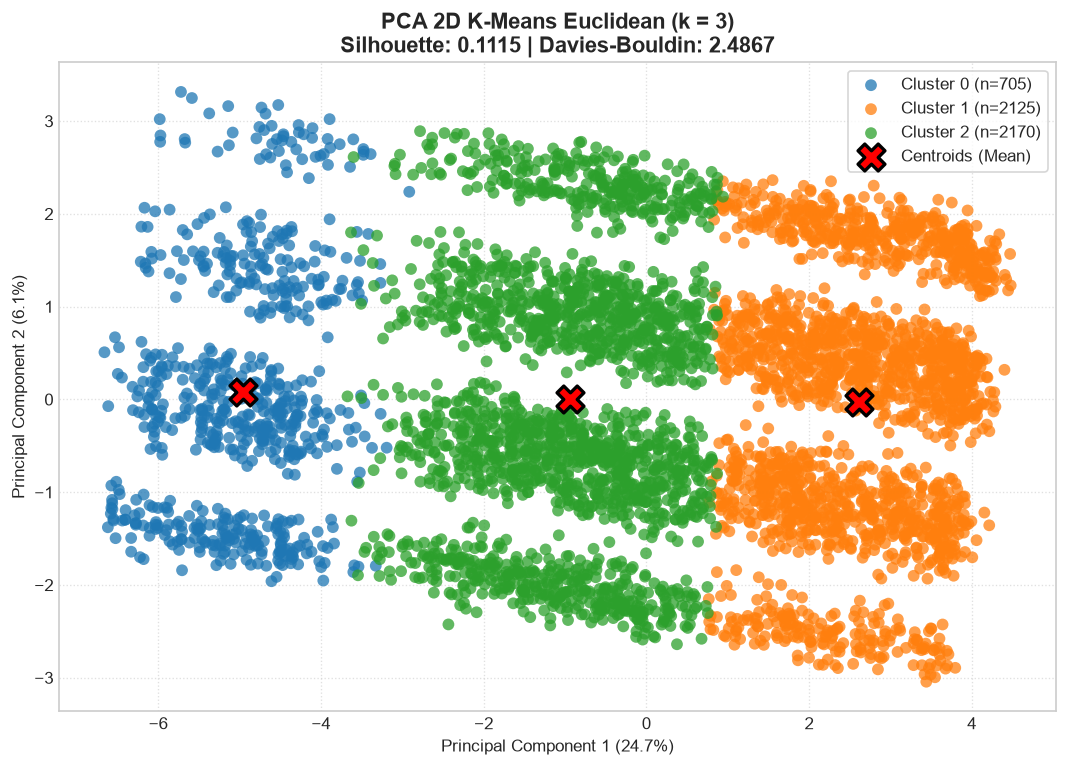

In [31]:
plt.figure(
    figsize=(9, 6.5)
)

palette = sns.color_palette(
    'tab10',
    n_clusters
)

for k in range(n_clusters):

    mask = labels == k

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        color=palette[k],
        label=(
            f'Cluster {k} '
            f'(n={np.sum(mask)})'
        ),
        alpha=0.75,
        s=50,
        edgecolors='none'
    )

plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    marker='X',
    s=260,
    c='red',
    edgecolor='black',
    linewidth=2,
    label='Centroids (Mean)',
    zorder=10
)

plt.title(
    f'PCA 2D K-Means Euclidean '
    f'(k = {n_clusters})\n'
    f'Silhouette: {silhouette:.4f} | '
    f'Davies-Bouldin: {db_index:.4f}',
    fontsize=13,
    fontweight='bold'
)

plt.xlabel(
    'Principal Component 1 '
    f'({pca.explained_variance_ratio_[0] * 100:.1f}%)'
)

plt.ylabel(
    'Principal Component 2 '
    f'({pca.explained_variance_ratio_[1] * 100:.1f}%)'
)

plt.grid(
    True,
    linestyle=':',
    alpha=0.6
)

plt.legend(
    frameon=True,
    loc='best'
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        'cluster_euclidean.png'
    ),
    dpi=300
)

plt.show()

6. Analisis

6.1 Profil Cluster

In [32]:
df_analysis = X.copy()

df_analysis['KMeans_Cluster'] = labels

cluster_profile = (
    df_analysis
    .groupby('KMeans_Cluster')
    .mean()
)

cluster_profile

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
KMeans_Cluster,,,,,,,,,,,,,,,,,,,,,
0,41.983578,6288.643112,59.926241,5.905825,5.493164,6.230044,81.392103,81.187703,18.843298,18.502128,...,2.000000,1.567376,0.489362,0.500709,0.458156,0.994326,0.478014,0.514233,1.575887,1.953191
1,41.982515,6336.362401,35.445647,5.616949,5.477139,7.387550,17.034291,17.596301,82.939433,82.891765,...,0.021647,1.543529,0.491765,0.486588,0.496000,0.000000,0.488941,0.509447,1.483765,0.045176
2,41.295345,6228.556447,49.582488,5.486459,5.570784,6.771014,51.017650,50.946642,49.081129,48.767742,...,0.999078,1.510138,0.475576,0.500922,0.496774,0.000000,0.487097,0.497513,1.504608,0.978341


6.2 Perbandingan Cluster dengan Burnout Risk

In [33]:
comparison = pd.crosstab(
    df['KMeans_Cluster'],
    df['Burnout_Risk']
)

comparison

comparison_percentage = pd.crosstab(
    df['KMeans_Cluster'],
    df['Burnout_Risk'],
    normalize='index'
) * 100

comparison_percentage.round(2)

Burnout_Risk,High,Low,Moderate
KMeans_Cluster,,,
0,90.78,0.00,9.22
1,0.00,95.48,4.52
2,16.91,20.83,62.26


6.3 Analisis Centroid

In [34]:
centroid_original = scaler.inverse_transform(
    kmeans.cluster_centers_
)

centroid_original = pd.DataFrame(
    centroid_original,
    columns=X.columns
)

centroid_original.index.name = 'Cluster'

centroid_original

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
Cluster,,,,,,,,,,,,,,,,,,,,,
0,41.983578,6288.643112,59.926241,5.905825,5.493164,6.230044,81.392103,81.187703,18.843298,18.502128,...,2.000000,1.567376,0.489362,0.500709,0.458156,9.943262e-01,0.478014,0.514233,1.575887,1.953191
1,41.982515,6336.362401,35.445647,5.616949,5.477139,7.387550,17.034291,17.596301,82.939433,82.891765,...,0.021647,1.543529,0.491765,0.486588,0.496000,-4.996004e-16,0.488941,0.509447,1.483765,0.045176
2,41.295345,6228.556447,49.582488,5.486459,5.570784,6.771014,51.017650,50.946642,49.081129,48.767742,...,0.999078,1.510138,0.475576,0.500922,0.496774,-4.996004e-16,0.487097,0.497513,1.504608,0.978341
